In [1]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

from sklearn.metrics import accuracy_score, classification_report


In [2]:

vocab_size = 10000
max_len = 200

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

x_train = pad_sequences(
    x_train, maxlen=max_len, padding="post"
)
x_test = pad_sequences(
    x_test, maxlen=max_len, padding="post"
)

x_train = x_train.astype("float32") / vocab_size
x_test = x_test.astype("float32") / vocab_size

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (25000, 200)
Testing data shape: (25000, 200)


In [3]:

input_layer = Input(shape=(max_len,))

# Encoder
encoded = Dense(128, activation="relu")(input_layer)
encoded = Dense(64, activation="relu")(encoded)
latent = Dense(32, activation="relu", name="latent_layer")(encoded)

# Decoder
decoded = Dense(64, activation="relu")(latent)
decoded = Dense(128, activation="relu")(decoded)
decoded = Dense(max_len, activation="sigmoid")(decoded)

autoencoder = Model(input_layer, decoded)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        25,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_layer (Dense)            │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 200)            │        25,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 72,296 (282.41 KB)

 Trainable params: 72,296 (282.41 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:

history_ae = autoencoder.fit(
    x_train,
    x_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)


Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0439 - val_loss: 0.0243
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0242 - val_loss: 0.0243
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0241 - val_loss: 0.0243
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0241 - val_loss: 0.0242
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0240 - val_loss: 0.0238


In [5]:

encoder = Model(input_layer, latent)

X_train_features = encoder.predict(x_train, verbose=0)
X_test_features = encoder.predict(x_test, verbose=0)

print("Training features:", X_train_features.shape)
print("Testing features:", X_test_features.shape)


Training features: (25000, 32)
Testing features: (25000, 32)


In [6]:

classifier_input = Input(shape=(32,))

x = Dense(16, activation="relu")(classifier_input)
output = Dense(1, activation="sigmoid")(x)

classifier = Model(classifier_input, output)

classifier.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

classifier.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545 (2.13 KB)

 Trainable params: 545 (2.13 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

history_clf = classifier.fit(
    X_train_features,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)


Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4951 - loss: 0.6965 - val_accuracy: 0.4974 - val_loss: 0.6945
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5074 - loss: 0.6938 - val_accuracy: 0.4922 - val_loss: 0.6995
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5041 - loss: 0.6943 - val_accuracy: 0.5006 - val_loss: 0.6937
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5123 - loss: 0.6930 - val_accuracy: 0.5134 - val_loss: 0.6924
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5159 - loss: 0.6922 - val_accuracy: 0.5156 - val_loss: 0.6930


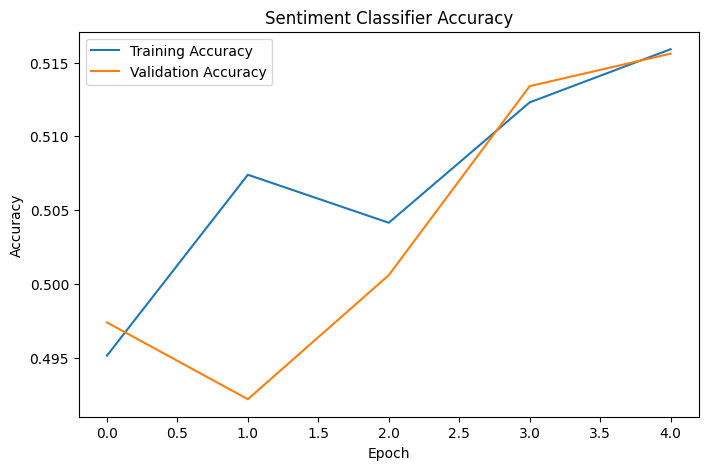

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history_clf.history["accuracy"], label="Training Accuracy")
plt.plot(history_clf.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Sentiment Classifier Accuracy")
plt.legend()
plt.show()


In [9]:

y_prob = classifier.predict(X_test_features, verbose=0)
y_pred = (y_prob > 0.5).astype(int).ravel()

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))


Accuracy: 0.50544

Classification Report:
              precision    recall  f1-score   support

    Negative       0.50      0.87      0.64     12500
    Positive       0.52      0.14      0.22     12500

    accuracy                           0.51     25000
   macro avg       0.51      0.51      0.43     25000
weighted avg       0.51      0.51      0.43     25000



In [10]:

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


In [11]:

original_dim = 784
latent_dim = 2
batch_size = 128

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:03<00:00, 2.53MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 523kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.43MB/s]

Training samples: 60000
Testing samples: 10000


In [12]:

class VAE(nn.Module):
    def __init__(self, original_dim=784, latent_dim=2):
        super().__init__()

        # Encoder
        self.enc_fc1 = nn.Linear(original_dim, 256)
        self.enc_fc2 = nn.Linear(256, 64)

        self.fc_mean = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        # Decoder
        self.dec_fc1 = nn.Linear(latent_dim, 64)
        self.dec_fc2 = nn.Linear(64, 256)
        self.dec_out = nn.Linear(256, original_dim)

    def encode(self, x):
        h = F.relu(self.enc_fc1(x))
        h = F.relu(self.enc_fc2(h))

        return self.fc_mean(h), self.fc_logvar(h)

    def reparameterize(self, z_mean, z_logvar):
        std = torch.exp(0.5 * z_logvar)
        epsilon = torch.randn_like(std)

        return z_mean + std * epsilon

    def decode(self, z):
        h = F.relu(self.dec_fc1(z))
        h = F.relu(self.dec_fc2(h))

        return torch.sigmoid(self.dec_out(h))

    def forward(self, x):
        z_mean, z_logvar = self.encode(x)
        z = self.reparameterize(z_mean, z_logvar)
        reconstruction = self.decode(z)

        return reconstruction, z_mean, z_logvar


model = VAE(original_dim, latent_dim).to(device)
print(model)


VAE(
  (enc_fc1): Linear(in_features=784, out_features=256, bias=True)
  (enc_fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc_mean): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (dec_fc1): Linear(in_features=2, out_features=64, bias=True)
  (dec_fc2): Linear(in_features=64, out_features=256, bias=True)
  (dec_out): Linear(in_features=256, out_features=784, bias=True)
)


In [13]:

def vae_loss(reconstruction, x, z_mean, z_logvar):
    recon_loss = F.binary_cross_entropy(
        reconstruction, x, reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + z_logvar - z_mean.pow(2) - z_logvar.exp()
    )

    total_loss = recon_loss + kl_loss

    return total_loss, recon_loss, kl_loss


In [14]:

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 15

for epoch in range(1, epochs + 1):
    model.train()

    total_loss = 0.0
    total_recon = 0.0
    total_kl = 0.0
    n_samples = 0

    for x, _ in train_loader:
        x = x.to(device)

        optimizer.zero_grad()

        reconstruction, z_mean, z_logvar = model(x)

        loss, recon_loss, kl_loss = vae_loss(
            reconstruction, x, z_mean, z_logvar
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()
        n_samples += x.size(0)

    print(
        f"Epoch {epoch:2d}/{epochs} | "
        f"loss: {total_loss / n_samples:.4f} | "
        f"recon: {total_recon / n_samples:.4f} | "
        f"kl: {total_kl / n_samples:.4f}"
    )


Epoch  1/15 | loss: 196.7174 | recon: 193.5238 | kl: 3.1936
Epoch  2/15 | loss: 167.0140 | recon: 162.1580 | kl: 4.8560
Epoch  3/15 | loss: 162.0326 | recon: 156.8965 | kl: 5.1360
Epoch  4/15 | loss: 158.0729 | recon: 152.6371 | kl: 5.4358
Epoch  5/15 | loss: 155.4076 | recon: 149.7854 | kl: 5.6222
Epoch  6/15 | loss: 153.4518 | recon: 147.6972 | kl: 5.7546
Epoch  7/15 | loss: 151.8878 | recon: 146.0047 | kl: 5.8831
Epoch  8/15 | loss: 150.5142 | recon: 144.5419 | kl: 5.9723
Epoch  9/15 | loss: 149.3175 | recon: 143.2665 | kl: 6.0510
Epoch 10/15 | loss: 148.3644 | recon: 142.2445 | kl: 6.1199
Epoch 11/15 | loss: 147.4293 | recon: 141.2373 | kl: 6.1920
Epoch 12/15 | loss: 146.7240 | recon: 140.4987 | kl: 6.2253
Epoch 13/15 | loss: 146.1017 | recon: 139.8278 | kl: 6.2738
Epoch 14/15 | loss: 145.4736 | recon: 139.1759 | kl: 6.2977
Epoch 15/15 | loss: 144.8872 | recon: 138.5440 | kl: 6.3432


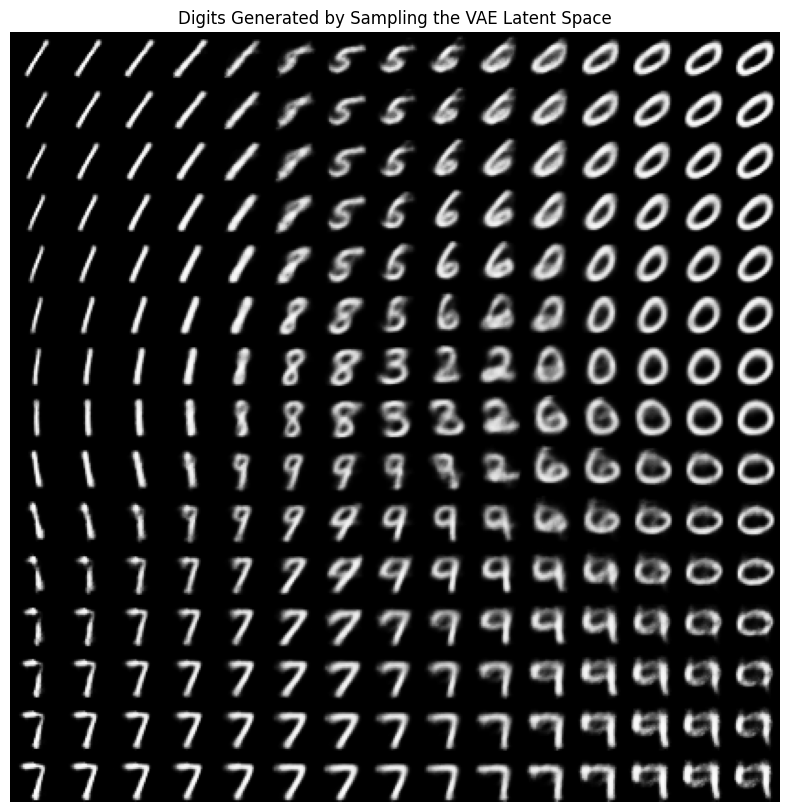

In [15]:

model.eval()

n = 15
digit_size = 28

figure = np.zeros((digit_size * n, digit_size * n))

grid_x = np.linspace(-3, 3, n)
grid_y = np.linspace(-3, 3, n)[::-1]

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

            z_sample = torch.tensor(
                [[xi, yi]], dtype=torch.float32
            ).to(device)

            x_decoded = model.decode(z_sample).cpu().numpy()
            digit = x_decoded[0].reshape(digit_size, digit_size)

            figure[
                i * digit_size:(i + 1) * digit_size,
                j * digit_size:(j + 1) * digit_size
            ] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="Greys_r")
plt.axis("off")
plt.title("Digits Generated by Sampling the VAE Latent Space")
plt.show()


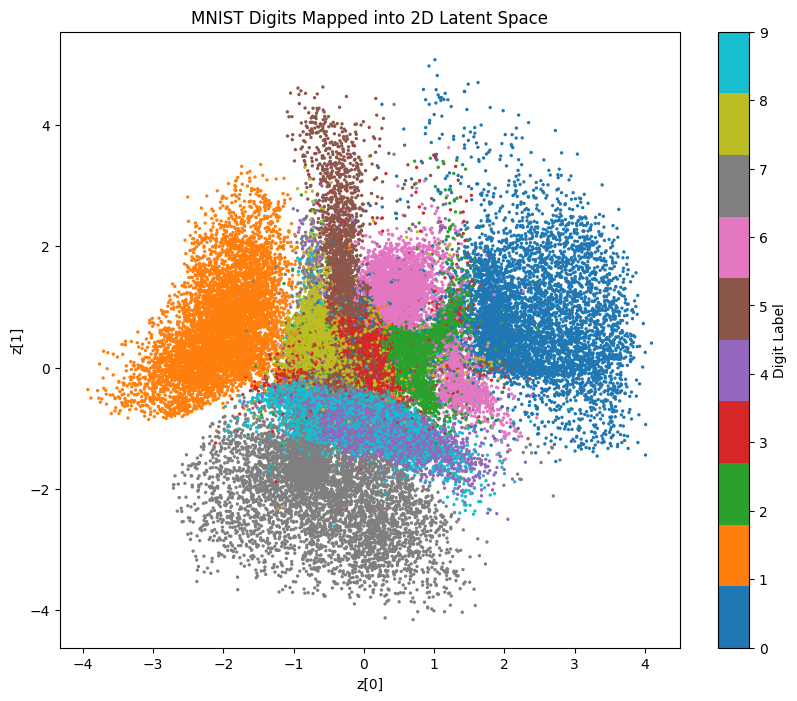

VAE experiment completed.


In [16]:

all_z_mean = []
all_labels = []

with torch.no_grad():
    for x, y in train_loader:
        x = x.to(device)

        z_mean, _ = model.encode(x)

        all_z_mean.append(z_mean.cpu().numpy())
        all_labels.append(y.numpy())

all_z_mean = np.concatenate(all_z_mean, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    all_z_mean[:, 0],
    all_z_mean[:, 1],
    c=all_labels,
    cmap="tab10",
    s=2
)

plt.colorbar(scatter, label="Digit Label")
plt.xlabel("z[0]")
plt.ylabel("z[1]")
plt.title("MNIST Digits Mapped into 2D Latent Space")
plt.show()

print("VAE experiment completed.")
